['title', 'year', 'genre', 'rating', 'votes', 'duration', 'budget', 'gross', 'type']
Число строк данных (без заголовка): 11272

Названия столбцов: ['title', 'year', 'genre', 'rating', 'votes', 'duration', 'budget', 'gross', 'type']
запись 1 
title: Kate & Leopold
year: 2001
genre: Comedy
rating: 6.4
votes: 77852
duration: 118
budget: 48000000
gross: 76019048
type: movie


запись 2 
title: I figli del fuoco
year: 1990
genre: Horror
rating: 4.8
votes: 2252
duration: 97
budget: 5500000
gross: 50367
type: movie


запись 3 
title: Le avventure di Ford Fairlane
year: 1990
genre: Action
rating: 6.5
votes: 16914
duration: 104
budget: 20000000
gross: 21413502
type: movie


запись 4 
title: Air America
year: 1990
genre: Action
rating: 5.8
votes: 26579
duration: 113
budget: 35000000
gross: 33461269
type: movie


запись 5 
title: Alice
year: 1990
genre: Comedy
rating: 6.6
votes: 13112
duration: 106
budget: 12000000
gross: 7331647
type: movie



Минимальный год выпуска: 1990
Максимальный год выпуск

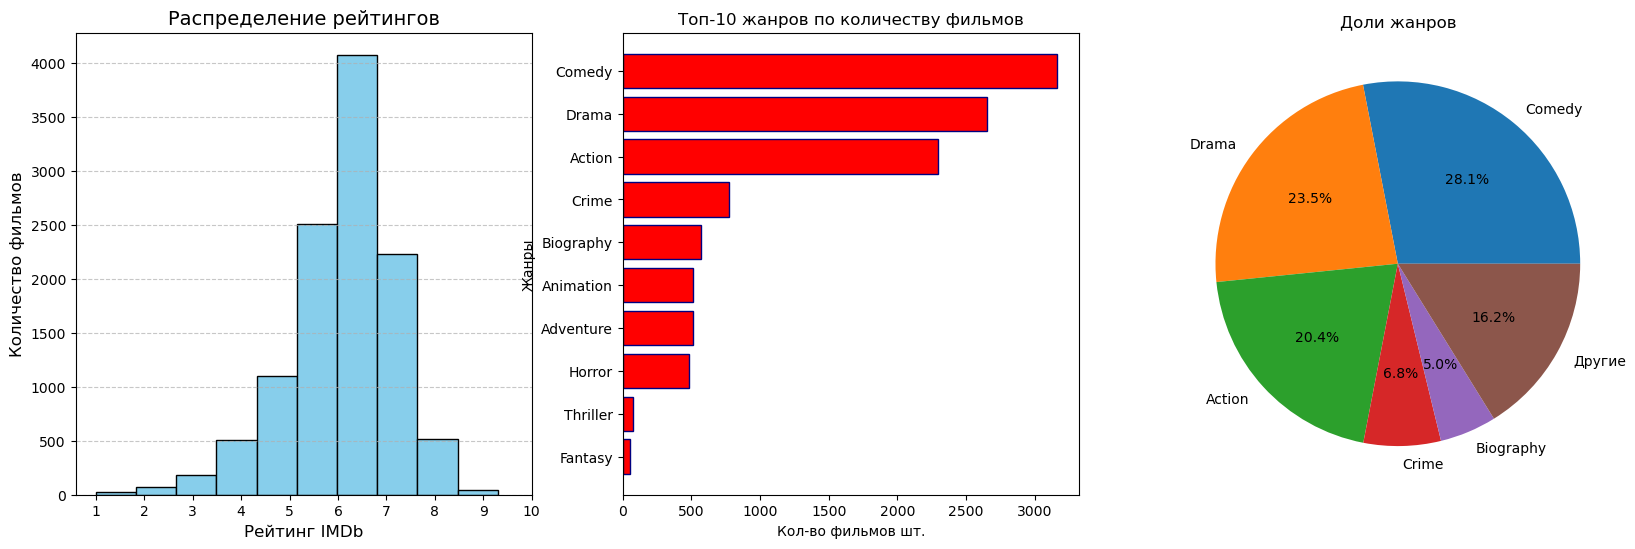

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

with open("movies.txt", "r", encoding="utf-8") as log:
    lines = log.readlines()

title = lines[0].strip()
head = title.split(";")
print(head)

data = []

for line in lines[1:]:
    parts = line.strip().split(';')
    record = {
        "title": parts[0],
        "year": int(parts[1]),
        "genre": parts[2],
        "rating": float(parts[3]),
        "votes": int(parts[4]),
        "duration": int(parts[5]),
        "budget": int(parts[6]),
        "gross": int(parts[7]),
        "type": parts[8],
        }
    data.append(record)

print(f"Число строк данных (без заголовка): {len(data)}")

print(f"\nНазвания столбцов: {head}")
i = 1
for record in data[:5]:
    print(f"запись {i} ")
    for key, value in record.items():
        print(f"{key}: {value}")
    print("\n")
    i += 1

years = [record['year'] for record in data]
min_year = min(years)
max_year = max(years)

print(f"\nМинимальный год выпуска: {min_year}")
print(f"Максимальный год выпуска: {max_year}")



#Часть 2

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

#График 1 Гистограмма распределения рейтингов
d_rati = [record['rating'] for record in data]
ax1.hist(d_rati, color='skyblue', edgecolor='black')
ax1.set_title('Распределение рейтингов', fontsize=14)
ax1.set_xlabel('Рейтинг IMDb', fontsize=12)
ax1.set_ylabel('Количество фильмов', fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.set_xticks(range(1, 11))

# #График 2 Столбчатая диаграмма топ-10 жанров по количеству фильмов.
# Данные для графика
d_genre = [record['genre'] for record in data]
counts_genre = {}
for x in d_genre:
    counts_genre[x] = counts_genre.get(x, 0) + 1
top_10 = sorted(counts_genre.items(), key=lambda kv: kv[1], reverse=True)[:10]
genres_10 = [item[0] for item in top_10]
counts_10 = [item[1] for item in top_10]
counts_10.reverse()
genres_10.reverse()
#Сам график
ax2.barh(genres_10, counts_10, color="red", edgecolor='navy')
ax2.set_title("Топ-10 жанров по количеству фильмов")
ax2.set_xlabel("Кол-во фильмов шт.")
ax2.set_ylabel("Жанры")

# График 3 Круговая диаграмма распределения фильмов по жанрам (топ-5 жанров + категория «Другие»)
top_5 = sorted(counts_genre.items(), key=lambda kv: kv[1], reverse=True)[:5]
ano_f_3 = sorted(counts_genre.items(), key=lambda kv: kv[1], reverse=True)[5:]
genres_5 = [item[0] for item in top_5]
counts_5 = [item[1] for item in top_5]

counts_ano = [item[1] for item in ano_f_3]
sum_ano = sum(counts_ano)
genres_3 = genres_5 + ['Другие']
counts_3 = counts_5 + [sum_ano]


ax3.pie(counts_3, labels=genres_3, autopct='%1.1f%%')
ax3.set_title("Доли жанров")


#Часть 3


# собираем рейтинги в словарь год: [список рейтингов]
ratings_by_year = {}
for record in data:
    year = record['year']
    if year >= 1990: # Берем только с 1990 года
        if year not in ratings_by_year:
            ratings_by_year[year] = []
        ratings_by_year[year].append(record['rating'])



avg_ratings_by_year = {}
for year, r_list in ratings_by_year.items():
    avg_ratings_by_year[year] = sum(r_list) / len(r_list)

years_sorted = sorted(avg_ratings_by_year.keys())
avg_ratings_sorted = [avg_ratings_by_year[y] for y in years_sorted]




print(years_sorted)













# Показываем окно с графиками
plt.show()







